# CLIP ViT-B/16 on AwA2

**Phase I, RQ1** We treat OpenAI's CLIP ViT-B/16 as a black box and run zero-shot classification on a fixed 5,000-image subset of Animals with Attributes 2 (AwA2) (50 classes, 100 images each). The notebook then looks at where the model goes wrong.

**Phase I, RQ2** We explore whether animal classes that share more visual attributes are more likely to be confused by CLIP. Using 33 appearance related attributes from AwA2 and CLIP predictions on the same fixed subset, we compare attribute similarity with classification errors across all 50 animal classes.

Pipeline:
1. Load the subset and check that every image exists.
2. Build 50 text embeddings from a prompt template and score every image against them.
3. Compute accuracy, per-class accuracy and the 50 x 50 confusion matrix.
4. Rank the most frequent confusions, directed (A predicted as B) and undirected (A and B mixed up in either direction).
5. Test whether errors stay inside groups of visually similar animals more often than chance gives.
6. Look at confidence, at the rank of the true class, and at example images.
7. Load the AwA2 attribute data and select 33 visual attributes.
8. Compute Jaccard similarity for all 1,225 unique animal pairs and visualize the similarity patterns.
9. Load the CLIP predictions from RQ1 and calculate class normalized confusion rates.
10. Compare attribute similarity with confusion rates (scatterplot).
11. Measure the relationship using Spearman correlation and test the significance with a permutation test.
12. Examine misclassified images to investigate confusion patterns and explanations.

## Setup and configuration

In [ ]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import open_clip
import contextlib

from PIL import Image
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
from sklearn.metrics import pairwise_distances

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Local paths
CSV_PATH = Path("awa2_subset_5000.csv")
IMAGE_ROOT = Path("Animals_with_Attributes2 2/JPEGImages")
META_DIR = Path("Animals_with_Attributes2")

OUT_DIR = Path("awa2_phase1_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# CLIP configuration
MODEL_NAME = "ViT-B-16-quickgelu"
PRETRAINED = "openai"
TEMPLATES = ["a photo of a {}."]

BATCH_SIZE = 128
NUM_WORKERS = 0
RECOMPUTE = False

LOGITS_PATH = OUT_DIR / f"clip_logits_{MODEL_NAME}.npy"

# Device
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("Device:", DEVICE)

sns.set_theme(style="white", context="notebook")

Device: mps


## RQ 1

## 2. Load the subset

In [4]:
df = pd.read_csv(CSV_PATH)
df["full_path"] = df["image_path"].map(lambda p: IMAGE_ROOT / p)

missing = [str(p) for p in df["full_path"] if not p.exists()]
assert not missing, f"{len(missing)} images not found, first few: {missing[:3]}. Check IMAGE_ROOT."

# AwA2 folder names use "+" for spaces; the prompts need plain names.
df["true_name"] = df["true_label"].str.replace("+", " ", regex=False)
names = sorted(df["true_name"].unique())
N = len(names)
name_to_idx = {n: i for i, n in enumerate(names)}
df["label_idx"] = df["true_name"].map(name_to_idx)

print(f"{len(df)} images, {N} classes")
print("images per class:", df["true_name"].value_counts().unique())
df.head()

5000 images, 50 classes
images per class: [100]


,image_path,true_label,full_path,true_name,label_idx
0,antelope/antelope_10014.jpg,antelope,Animals_with_Attributes2 2/JPEGImages/antelope...,antelope,0
1,antelope/antelope_10024.jpg,antelope,Animals_with_Attributes2 2/JPEGImages/antelope...,antelope,0
2,antelope/antelope_10052.jpg,antelope,Animals_with_Attributes2 2/JPEGImages/antelope...,antelope,0
3,antelope/antelope_10055.jpg,antelope,Animals_with_Attributes2 2/JPEGImages/antelope...,antelope,0
4,antelope/antelope_10062.jpg,antelope,Animals_with_Attributes2 2/JPEGImages/antelope...,antelope,0


## 3. Zero-shot CLIP

Each class name goes through the template, gets encoded, and is L2-normalized. An image is scored by cosine similarity to all 50 text embeddings, scaled by CLIP's learned temperature (`logit_scale`, about 100). Softmax over those 50 scores gives the probabilities used below. The label set is closed: the model can only pick one of the 50 AwA2 classes.

In [5]:
need_inference = RECOMPUTE or not LOGITS_PATH.exists()

if need_inference:
    import open_clip

    model, _, preprocess = open_clip.create_model_and_transforms(MODEL_NAME, pretrained=PRETRAINED)
    tokenizer = open_clip.get_tokenizer(MODEL_NAME)
    model = model.to(DEVICE).eval()

    @torch.no_grad()
    def build_text_features(class_names, templates):
        feats = []
        for c in class_names:
            tokens = tokenizer([t.format(c) for t in templates]).to(DEVICE)
            f = model.encode_text(tokens).float()
            f = f / f.norm(dim=-1, keepdim=True)
            f = f.mean(dim=0)
            feats.append(f / f.norm())
        return torch.stack(feats)

    text_features = build_text_features(names, TEMPLATES)
    print("text features:", tuple(text_features.shape))
else:
    print(f"Using cached logits from {LOGITS_PATH}")

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

text features: (50, 512)


In [8]:
class ImageFolderCSV(Dataset):
    def __init__(self, paths, transform):
        self.paths, self.transform = list(paths), transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            return self.transform(im.convert("RGB"))

if need_inference:
    loader = DataLoader(
        ImageFolderCSV(df["full_path"], preprocess),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
    )
    logit_scale = model.logit_scale.exp().item()
    amp = torch.autocast("cuda") if DEVICE == "cuda" else contextlib.nullcontext()

    chunks = []
    with torch.no_grad():
        for imgs in tqdm(loader, desc="CLIP inference"):
            with amp:
                f = model.encode_image(imgs.to(DEVICE))
            f = f.float()
            f = f / f.norm(dim=-1, keepdim=True)
            chunks.append((logit_scale * f @ text_features.T).cpu())
    logits = torch.cat(chunks).numpy()
    np.save(LOGITS_PATH, logits)
    print("saved", LOGITS_PATH)
else:
    logits = np.load(LOGITS_PATH)

assert logits.shape == (len(df), N), logits.shape

CLIP inference:   0%|          | 0/40 [00:00<?, ?it/s]

saved awa2_phase1_outputs/clip_logits_ViT-B-16-quickgelu.npy


In [9]:
def softmax(x):
    x = x - x.max(axis=1, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=1, keepdims=True)

probs = softmax(logits)
rows = np.arange(len(df))

df["pred_idx"] = probs.argmax(1)
df["pred_name"] = df["pred_idx"].map(lambda i: names[i])
df["correct"] = df["pred_idx"] == df["label_idx"]
df["confidence"] = probs.max(1)
df["true_prob"] = probs[rows, df["label_idx"]]
# rank of the true class among the 50 scores (1 = top prediction)
df["true_rank"] = 1 + (probs > df["true_prob"].to_numpy()[:, None]).sum(1)
df["top5_correct"] = df["true_rank"] <= 5

df[["image_path", "true_name", "pred_name", "correct", "confidence", "true_rank"]].head()

,image_path,true_name,pred_name,correct,confidence,true_rank
0,antelope/antelope_10014.jpg,antelope,antelope,True,0.857362,1
1,antelope/antelope_10024.jpg,antelope,antelope,True,0.976550,1
2,antelope/antelope_10052.jpg,antelope,antelope,True,0.991317,1
3,antelope/antelope_10055.jpg,antelope,antelope,True,0.987785,1
4,antelope/antelope_10062.jpg,antelope,antelope,True,0.991623,1


## 4. Overall and per-class accuracy

In [10]:
acc = df["correct"].mean()
top5 = df["top5_correct"].mean()

# bootstrap 95% CI over images
rng = np.random.default_rng(SEED)
boot = [rng.choice(df["correct"].to_numpy(), size=len(df), replace=True).mean() for _ in range(2000)]
lo, hi = np.percentile(boot, [2.5, 97.5])

print(f"top-1 accuracy: {acc:.4f}  (95% bootstrap CI {lo:.4f} to {hi:.4f})")
print(f"top-5 accuracy: {top5:.4f}")
print(f"errors: {(~df['correct']).sum()} of {len(df)}")

top-1 accuracy: 0.9208  (95% bootstrap CI 0.9134 to 0.9286)
top-5 accuracy: 0.9976
errors: 396 of 5000


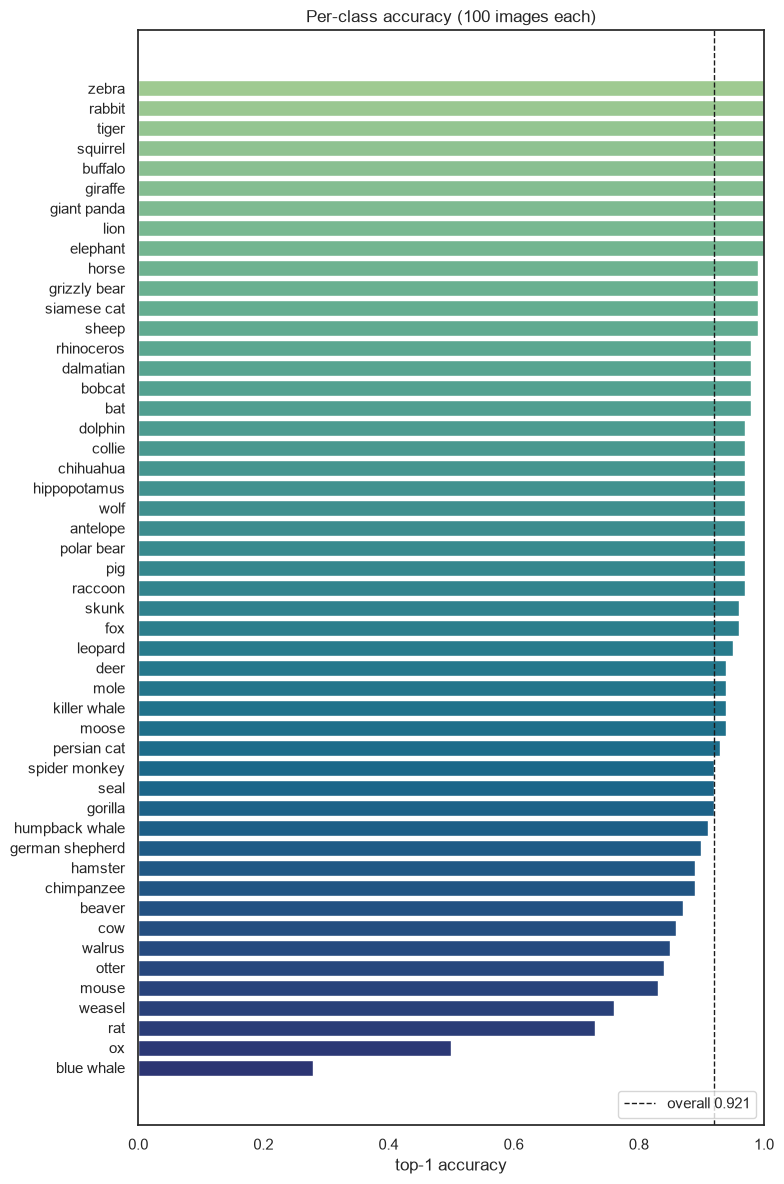

Ten weakest classes


,accuracy,top5,mean_conf
true_name,,,
blue whale,0.28,1.00,0.714
ox,0.50,1.00,0.729
rat,0.73,0.97,0.683
weasel,0.76,0.98,0.753
mouse,0.83,0.98,0.762
otter,0.84,1.00,0.829
walrus,0.85,0.99,0.796
cow,0.86,1.00,0.770
beaver,0.87,0.99,0.838


In [11]:
per_class = (
    df.groupby("true_name")
      .agg(accuracy=("correct", "mean"), top5=("top5_correct", "mean"), mean_conf=("confidence", "mean"))
      .sort_values("accuracy")
)

fig, ax = plt.subplots(figsize=(8, 12))
ax.barh(per_class.index, per_class["accuracy"], color=sns.color_palette("crest", len(per_class))[::-1])
ax.axvline(acc, color="k", ls="--", lw=1, label=f"overall {acc:.3f}")
ax.set_xlabel("top-1 accuracy")
ax.set_xlim(0, 1)
ax.legend(loc="lower right")
ax.set_title("Per-class accuracy (100 images each)")
plt.tight_layout()
plt.savefig(OUT_DIR / "per_class_accuracy.png", dpi=150)
plt.show()

print("Ten weakest classes")
display(per_class.head(10).round(3))

In [ ]:
print(classification_report(df["label_idx"], df["pred_idx"], target_names=names, digits=3))

                 precision    recall  f1-score   support

       antelope      0.942     0.970     0.956       100
            bat      0.980     0.980     0.980       100
         beaver      0.853     0.870     0.861       100
     blue whale      0.848     0.280     0.421       100
         bobcat      0.916     0.980     0.947       100
        buffalo      0.758     1.000     0.862       100
      chihuahua      0.960     0.970     0.965       100
     chimpanzee      0.856     0.890     0.873       100
         collie      0.942     0.970     0.956       100
            cow      0.770     0.870     0.817       100
      dalmatian      1.000     0.980     0.990       100
           deer      0.959     0.940     0.949       100
        dolphin      0.970     0.970     0.970       100
       elephant      1.000     1.000     1.000       100
            fox      0.980     0.960     0.970       100
german shepherd      0.978     0.900     0.938       100
    giant panda      0.990    

## 5. Confusion matrix

Rows are true classes, columns are predictions, and each row is normalized to sum to 1. The first plot includes the diagonal. The second zeroes the diagonal so the errors are visible against a much darker background.

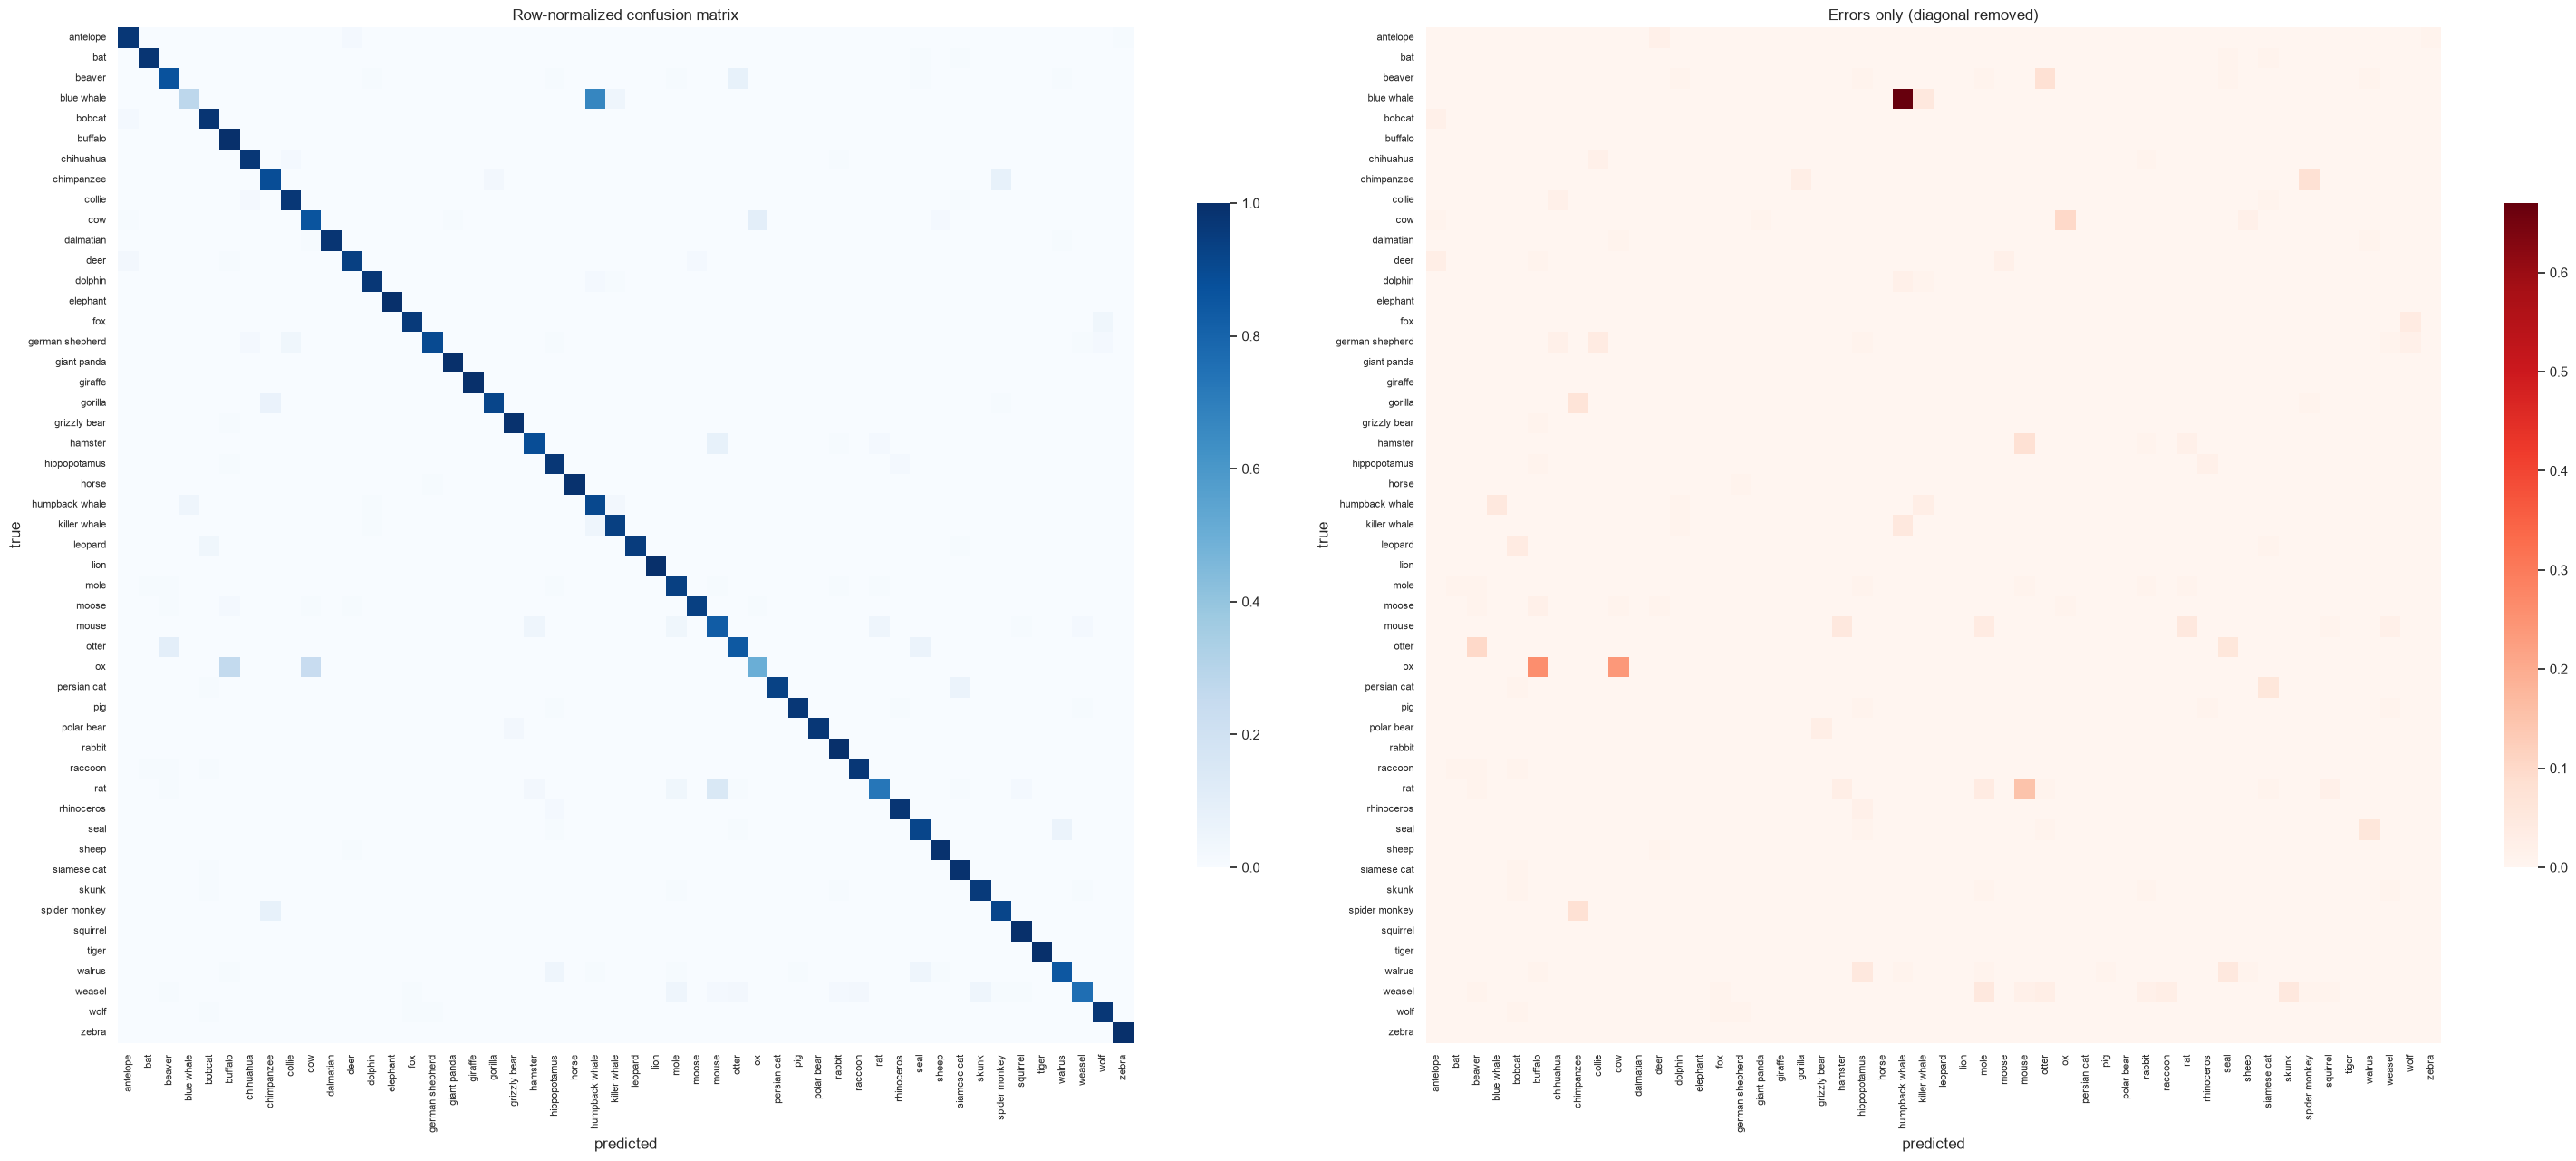

In [12]:
cm = confusion_matrix(df["label_idx"], df["pred_idx"], labels=range(N))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

fig, axes = plt.subplots(1, 2, figsize=(30, 13))
sns.heatmap(cm_norm, ax=axes[0], xticklabels=names, yticklabels=names, cmap="Blues",
            vmin=0, vmax=1, cbar_kws={"shrink": 0.6}, square=True)
axes[0].set_title("Row-normalized confusion matrix")

off_norm = cm_off / cm.sum(axis=1, keepdims=True)
sns.heatmap(off_norm, ax=axes[1], xticklabels=names, yticklabels=names, cmap="Reds",
            cbar_kws={"shrink": 0.6}, square=True)
axes[1].set_title("Errors only (diagonal removed)")

for ax in axes:
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.tick_params(axis="x", labelsize=8, rotation=90)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

pd.DataFrame(cm, index=names, columns=names).to_csv(OUT_DIR / "confusion_matrix_counts.csv")

## 6. Most frequent confusions

A directed pair (true A, predicted B) is not the same as (true B, predicted A). CLIP often has a bias, for example calling every small dog a "chihuahua" but rarely the reverse. The directed table shows that bias. The undirected table adds both directions and shows which two classes are hardest to tell apart.

In [14]:
directed = pd.DataFrame(
    [(names[i], names[j], cm[i, j], cm[i, j] / cm[i].sum())
     for i in range(N) for j in range(N) if i != j and cm[i, j] > 0],
    columns=["true", "predicted", "count", "rate_of_true_class"],
).sort_values("count", ascending=False).reset_index(drop=True)

undirected = pd.DataFrame(
    [(names[i], names[j], cm[i, j], cm[j, i], cm[i, j] + cm[j, i])
     for i in range(N) for j in range(i + 1, N) if cm[i, j] + cm[j, i] > 0],
    columns=["class_a", "class_b", "a_as_b", "b_as_a", "total"],
).sort_values("total", ascending=False).reset_index(drop=True)

print("Top 20 directed confusions")
display(directed.head(20))
print("Top 20 undirected confusions")
display(undirected.head(20))

directed.to_csv(OUT_DIR / "confusions_directed.csv", index=False)
undirected.to_csv(OUT_DIR / "confusions_undirected.csv", index=False)

Top 20 directed confusions


,true,predicted,count,rate_of_true_class
0,blue whale,humpback whale,67,0.67
1,ox,buffalo,26,0.26
2,ox,cow,24,0.24
3,rat,mouse,15,0.15
4,cow,ox,10,0.10
5,otter,beaver,10,0.10
6,beaver,otter,8,0.08
7,hamster,mouse,8,0.08
8,spider monkey,chimpanzee,8,0.08
9,chimpanzee,spider monkey,8,0.08


Top 20 undirected confusions


,class_a,class_b,a_as_b,b_as_a,total
0,blue whale,humpback whale,67,5,72
1,cow,ox,10,24,34
2,buffalo,ox,0,26,26
3,mouse,rat,5,15,20
4,beaver,otter,8,10,18
5,chimpanzee,spider monkey,8,8,16
6,hamster,mouse,8,5,13
7,seal,walrus,6,5,11
8,chimpanzee,gorilla,3,7,10
9,humpback whale,killer whale,3,5,8


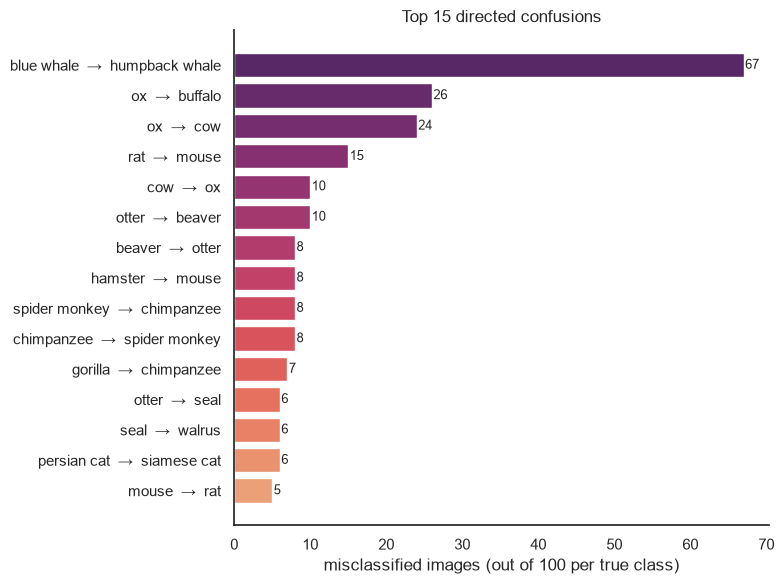

top  5 directed pairs cover 35.9% of all 396 errors
top 10 directed pairs cover 46.5% of all 396 errors
top 20 directed pairs cover 60.4% of all 396 errors


In [15]:
top = directed.head(15).iloc[::-1]
labels = top["true"] + "  →  " + top["predicted"]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(labels, top["count"], color=sns.color_palette("flare", len(top)))
for y, v in enumerate(top["count"]):
    ax.text(v + 0.2, y, str(v), va="center", fontsize=9)
ax.set_xlabel("misclassified images (out of 100 per true class)")
ax.set_title("Top 15 directed confusions")
sns.despine()
plt.tight_layout()
plt.savefig(OUT_DIR / "top_directed_confusions.png", dpi=150)
plt.show()

n_err = (~df["correct"]).sum()
for k in (5, 10, 20):
    share = directed.head(k)["count"].sum() / n_err
    print(f"top {k:>2} directed pairs cover {share:.1%} of all {n_err} errors")

In [16]:
rows_ = []
for i, c in enumerate(names):
    order = np.argsort(-cm_off[i])
    first, second = order[0], order[1]
    rows_.append({
        "class": c,
        "accuracy": cm[i, i] / cm[i].sum(),
        "errors": int(cm_off[i].sum()),
        "most_confused_with": names[first] if cm_off[i, first] else "-",
        "n_1": int(cm_off[i, first]),
        "second": names[second] if cm_off[i, second] else "-",
        "n_2": int(cm_off[i, second]),
    })
class_summary = pd.DataFrame(rows_).sort_values("accuracy").reset_index(drop=True)
class_summary.to_csv(OUT_DIR / "class_summary.csv", index=False)
display(class_summary.round(3))

,class,accuracy,errors,most_confused_with,n_1,second,n_2
0,blue whale,0.28,72,humpback whale,67,killer whale,5
1,ox,0.50,50,buffalo,26,cow,24
2,rat,0.73,27,mouse,15,mole,4
3,weasel,0.76,24,skunk,5,mole,5
4,mouse,0.83,17,hamster,5,rat,5
5,otter,0.84,16,beaver,10,seal,6
6,walrus,0.85,15,hippopotamus,5,seal,5
7,cow,0.86,14,ox,10,sheep,2
8,beaver,0.87,13,otter,8,dolphin,1
9,chimpanzee,0.89,11,spider monkey,8,gorilla,3


## 7. Do errors stay inside groups of similar animals?

Pairs on their own do not say whether CLIP is confusing *similar* animals or just making scattered mistakes. To test this, the 50 classes are placed into hand-picked groups by taxonomy and general appearance. The grouping is a judgment call and can be edited. Every class must appear in exactly one group.

Baseline: if an error landed on a uniformly random wrong class, the chance that it stays in the true class's group is `(group size - 1) / 49`. Comparing the observed share of within-group errors to that baseline gives a simple effect size.

In [17]:
GROUPS = {
    "cetaceans":          ["blue whale", "humpback whale", "killer whale", "dolphin"],
    "felids":             ["leopard", "lion", "tiger", "bobcat", "persian cat", "siamese cat"],
    "canids":             ["chihuahua", "collie", "dalmatian", "german shepherd", "wolf", "fox"],
    "bears":              ["grizzly bear", "polar bear", "giant panda"],
    "hoofed":             ["antelope", "deer", "moose", "ox", "cow", "buffalo", "horse", "zebra",
                           "sheep", "pig", "giraffe"],
    "small rodent-like":  ["mouse", "rat", "hamster", "squirrel", "beaver", "rabbit", "mole"],
    "primates":           ["chimpanzee", "gorilla", "spider monkey"],
    "pinnipeds and otter": ["seal", "walrus", "otter"],
    "small carnivores":   ["weasel", "skunk", "raccoon"],
    "megafauna":          ["elephant", "rhinoceros", "hippopotamus"],
    "other":              ["bat"],
}
group_of = {c: g for g, members in GROUPS.items() for c in members}
assert set(group_of) == set(names), (set(names) ^ set(group_of))
assert sum(len(m) for m in GROUPS.values()) == N

g = pd.Series(group_of)
group_size = g.map(g.value_counts())
expected_by_class = (group_size - 1) / (N - 1)

err = df[~df["correct"]].copy()
err["true_group"] = err["true_name"].map(group_of)
err["pred_group"] = err["pred_name"].map(group_of)
err["same_group"] = err["true_group"] == err["pred_group"]

observed = err["same_group"].mean()
expected = err["true_name"].map(expected_by_class).mean()
print(f"errors that stay inside the true class's group: {observed:.1%}")
print(f"expected if errors were spread uniformly over wrong classes: {expected:.1%}")
print(f"ratio observed / expected: {observed / expected:.2f}")

errors that stay inside the true class's group: 79.8%
expected if errors were spread uniformly over wrong classes: 10.1%
ratio observed / expected: 7.88


,errors,within_group,expected,n_classes,accuracy
true_group,,,,,
cetaceans,90,1.000,0.061,4,0.775
hoofed,84,0.929,0.204,11,0.924
small rodent-like,74,0.757,0.122,7,0.894
pinnipeds and otter,39,0.462,0.041,3,0.870
small carnivores,31,0.290,0.041,3,0.897
primates,27,1.000,0.041,3,0.910
canids,25,0.720,0.102,6,0.958
felids,15,0.867,0.102,6,0.975
megafauna,5,0.800,0.041,3,0.983


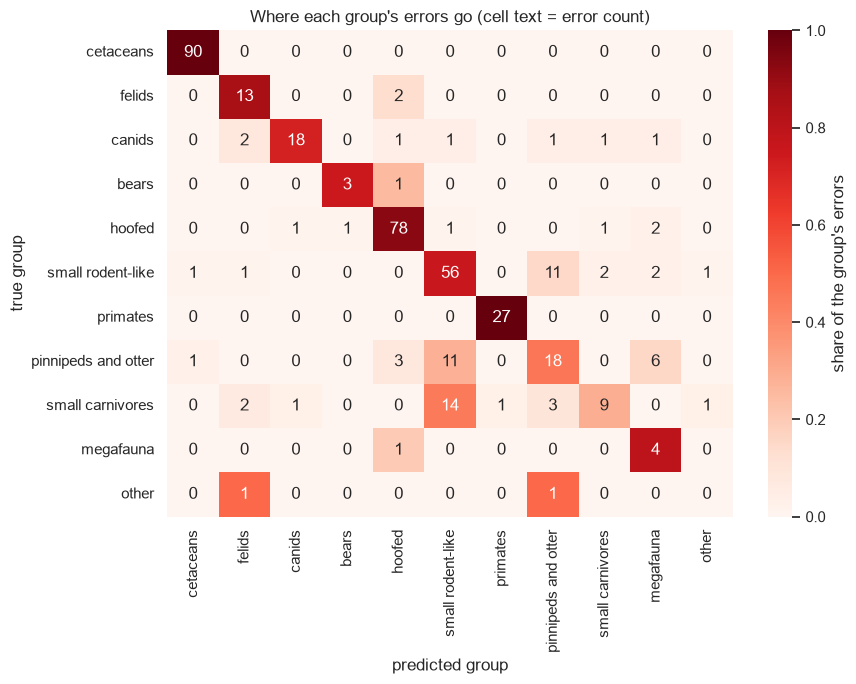

In [18]:
grp = (
    err.groupby("true_group")
       .agg(errors=("same_group", "size"), within_group=("same_group", "mean"))
)
grp["expected"] = [
    expected_by_class[[c for c in GROUPS[k]]].mean() for k in grp.index
]
grp["n_classes"] = [len(GROUPS[k]) for k in grp.index]
grp["accuracy"] = df.assign(tg=df["true_name"].map(group_of)).groupby("tg")["correct"].mean()
display(grp.sort_values("errors", ascending=False).round(3))

order = list(GROUPS)
gm = pd.crosstab(err["true_group"], err["pred_group"]).reindex(index=order, columns=order, fill_value=0)
gm_n = gm.div(gm.sum(axis=1).replace(0, np.nan), axis=0)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(gm_n, annot=gm, fmt="d", cmap="Reds", cbar_kws={"label": "share of the group's errors"}, ax=ax)
ax.set_xlabel("predicted group")
ax.set_ylabel("true group")
ax.set_title("Where each group's errors go (cell text = error count)")
plt.tight_layout()
plt.savefig(OUT_DIR / "group_error_flow.png", dpi=150)
plt.show()

## 8. Confidence and the rank of the true class

Two questions. Is the model less sure when it is wrong? And when it is wrong, how far down its list is the true class? If most errors have the true class at rank 2, the model was close and the confusion is a near miss.

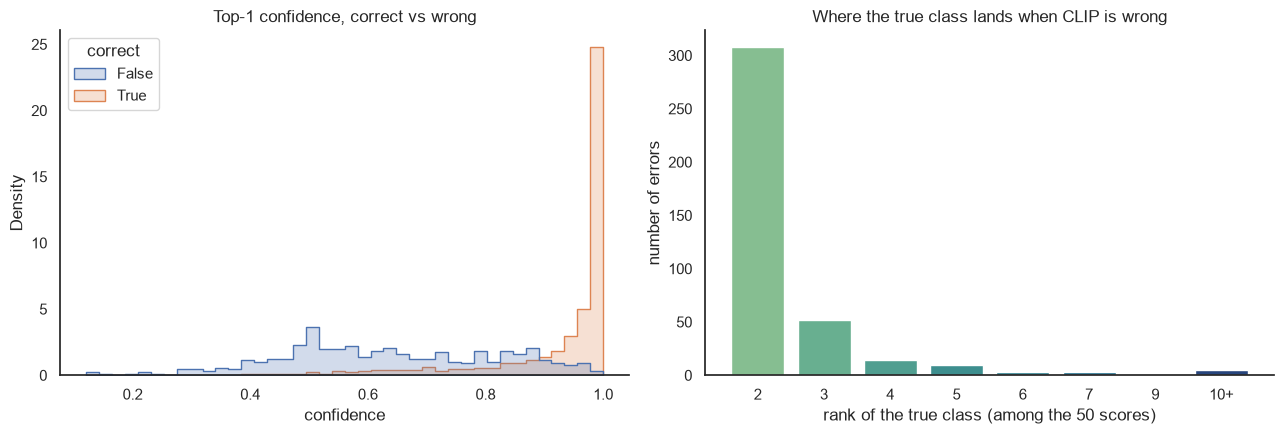

          count   mean    std    min    25%    50%    75%    max
correct                                                         
False     396.0  0.637  0.183  0.121  0.503  0.623  0.797  0.979
True     4604.0  0.924  0.125  0.166  0.919  0.982  0.995  1.000

errors with the true class at rank 2: 77.8%
errors with the true class in the top 5: 97.0%


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data=df, x="confidence", hue="correct", bins=40, stat="density", common_norm=False,
             element="step", ax=axes[0])
axes[0].set_title("Top-1 confidence, correct vs wrong")

rank_counts = err["true_rank"].clip(upper=10).value_counts().sort_index()
axes[1].bar(rank_counts.index.astype(str).str.replace("10", "10+"), rank_counts.values,
            color=sns.color_palette("crest", len(rank_counts)))
axes[1].set_xlabel("rank of the true class (among the 50 scores)")
axes[1].set_ylabel("number of errors")
axes[1].set_title("Where the true class lands when CLIP is wrong")
sns.despine()
plt.tight_layout()
plt.savefig(OUT_DIR / "confidence_and_rank.png", dpi=150)
plt.show()

print(df.groupby("correct")["confidence"].describe().round(3))
print(f"\nerrors with the true class at rank 2: {(err['true_rank'] == 2).mean():.1%}")
print(f"errors with the true class in the top 5: {(err['true_rank'] <= 5).mean():.1%}")

## 9. Example errors

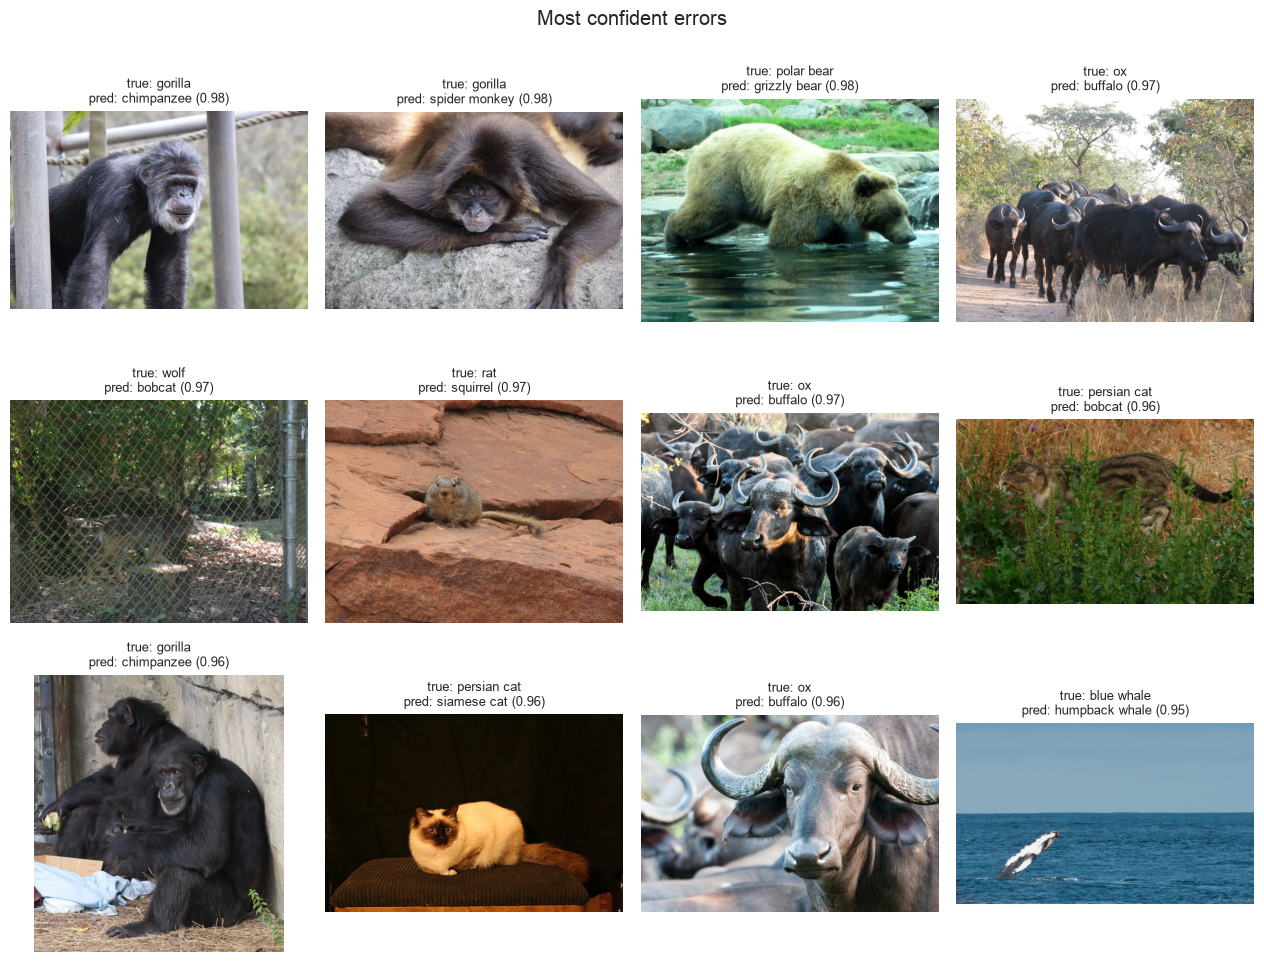

In [20]:
def show_images(frame, title, ncols=4, max_n=12):
    frame = frame.head(max_n)
    nrows = int(np.ceil(len(frame) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (_, r) in zip(axes, frame.iterrows()):
        with Image.open(r["full_path"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"true: {r['true_name']}\npred: {r['pred_name']} ({r['confidence']:.2f})", fontsize=9)
    fig.suptitle(title, y=1.0)
    plt.tight_layout()
    plt.show()

# the most confident mistakes overall
show_images(err.sort_values("confidence", ascending=False), "Most confident errors")

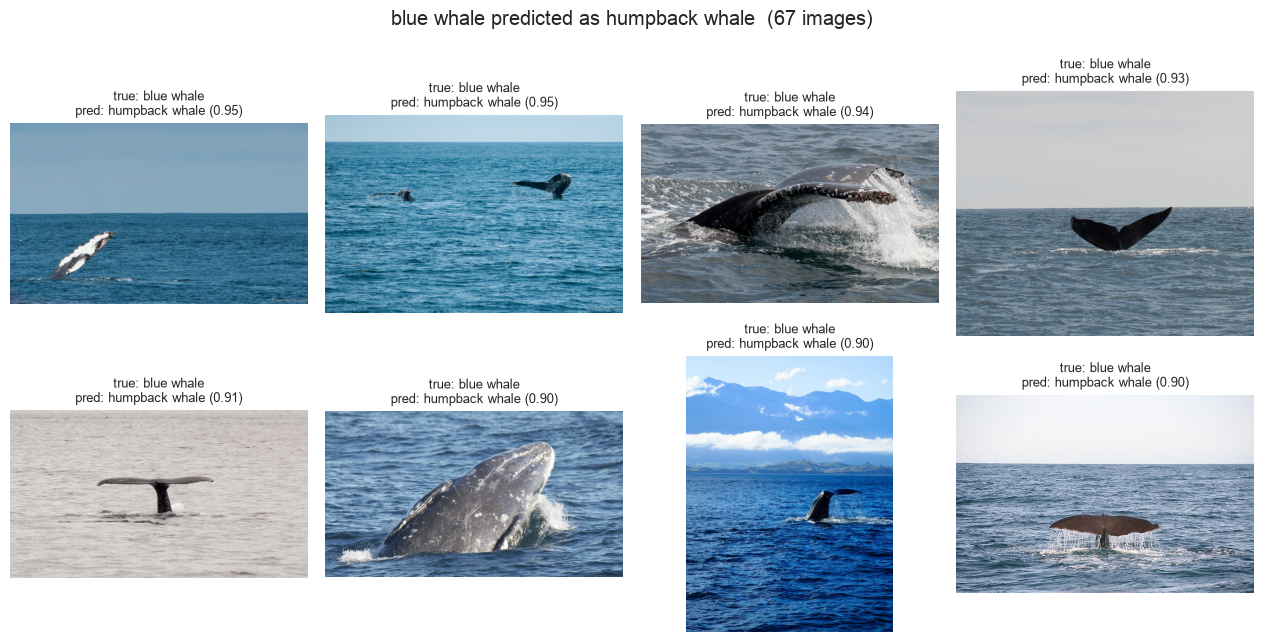

In [21]:
# examples for the single most frequent directed confusion
t, p = directed.loc[0, "true"], directed.loc[0, "predicted"]
pair_errs = err[(err["true_name"] == t) & (err["pred_name"] == p)].sort_values("confidence", ascending=False)
show_images(pair_errs, f"{t} predicted as {p}  ({len(pair_errs)} images)", max_n=8)

## 10. Save outputs and print a summary

In [22]:
# minimal file to share: same names as the original CSV ("+" instead of spaces)
share = pd.DataFrame({
    "image_path": df["image_path"],
    "true_label": df["true_label"],
    "predicted_label": df["pred_name"].str.replace(" ", "+", regex=False),
})
assert len(share) == 5000 and share["predicted_label"].isin(set(df["true_label"])).all()
share.to_csv(OUT_DIR / "clip_predictions.csv", index=False)
print("accuracy check:", (share["true_label"] == share["predicted_label"]).mean())
share.head()

accuracy check: 0.9208


,image_path,true_label,predicted_label
0,antelope/antelope_10014.jpg,antelope,antelope
1,antelope/antelope_10024.jpg,antelope,antelope
2,antelope/antelope_10052.jpg,antelope,antelope
3,antelope/antelope_10055.jpg,antelope,antelope
4,antelope/antelope_10062.jpg,antelope,antelope


In [23]:
df.drop(columns=["full_path"]).to_csv(OUT_DIR / "predictions.csv", index=False)
per_class.to_csv(OUT_DIR / "per_class_accuracy.csv")

print("=== RQ1 summary ===")
print(f"model: {MODEL_NAME} ({PRETRAINED}), templates: {TEMPLATES}")
print(f"top-1 {acc:.3f} | top-5 {top5:.3f} | errors {n_err}")
print("\nweakest classes:")
for c, r in per_class.head(5).iterrows():
    cs = class_summary.set_index("class").loc[c]
    print(f"  {c:<16} acc {r['accuracy']:.2f}  mostly predicted as {cs['most_confused_with']} ({cs['n_1']})")
print("\ntop directed confusions:")
for _, r in directed.head(5).iterrows():
    print(f"  {r['true']} -> {r['predicted']}: {r['count']}")
print("\ntop undirected pairs:")
for _, r in undirected.head(5).iterrows():
    print(f"  {r['class_a']} <-> {r['class_b']}: {r['total']} ({r['a_as_b']} + {r['b_as_a']})")
print(f"\nwithin-group errors: {observed:.1%} observed vs {expected:.1%} expected by chance")
print("\nfiles written to", OUT_DIR.resolve())

=== RQ1 summary ===
model: ViT-B-16-quickgelu (openai), templates: ['a photo of a {}.']
top-1 0.921 | top-5 0.998 | errors 396

weakest classes:
  blue whale       acc 0.28  mostly predicted as humpback whale (67)
  ox               acc 0.50  mostly predicted as buffalo (26)
  rat              acc 0.73  mostly predicted as mouse (15)
  weasel           acc 0.76  mostly predicted as skunk (5)
  mouse            acc 0.83  mostly predicted as hamster (5)

top directed confusions:
  blue whale -> humpback whale: 67
  ox -> buffalo: 26
  ox -> cow: 24
  rat -> mouse: 15
  cow -> ox: 10

top undirected pairs:
  blue whale <-> humpback whale: 72 (67 + 5)
  cow <-> ox: 34 (10 + 24)
  buffalo <-> ox: 26 (0 + 26)
  mouse <-> rat: 20 (5 + 15)
  beaver <-> otter: 18 (8 + 10)

within-group errors: 79.8% observed vs 10.1% expected by chance

files written to /Users/chimedrz/Documents/JKU AI - MSc/AI and vis/AwA2/awa2_phase1_outputs


## RQ2

## 1. AwA2 Attribute Data

In [24]:
data_dir = Path("Animals_with_Attributes2")

classes = pd.read_csv(
    data_dir / "classes.txt",
    sep=r"\s+",
    header=None,
    names=["id", "class_name"]
)

attributes = pd.read_csv(
    data_dir / "predicates.txt",
    sep=r"\s+",
    header=None,
    names=["id", "attribute"]
)

binary_matrix = np.loadtxt(
    data_dir / "predicate-matrix-binary.txt",
    dtype=int
)

attribute_df = pd.DataFrame(
    binary_matrix,
    index=classes["class_name"].tolist(),
    columns=attributes["attribute"].tolist()
)

print("Matrix shape:", attribute_df.shape)
display(attribute_df.head())

Matrix shape: (50, 85)


,black,white,blue,brown,gray,orange,red,yellow,patches,spots,...,water,tree,cave,fierce,timid,smart,group,solitary,nestspot,domestic
antelope,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,1,0,0,0
grizzly+bear,1,0,0,1,0,0,0,0,0,0,...,0,0,1,1,0,1,0,1,0,0
killer+whale,1,1,0,0,0,0,0,0,1,1,...,1,0,0,1,0,1,1,0,0,0
beaver,0,0,0,1,0,0,0,0,0,0,...,1,0,0,0,1,1,1,1,1,0
dalmatian,1,1,0,0,0,0,0,0,1,1,...,0,0,0,0,1,1,1,1,0,1


## Attribute overview

In [25]:
for i, attribute in enumerate(attribute_df.columns, 1):
    print(f"{i:02d}. {attribute}")

01. black
02. white
03. blue
04. brown
05. gray
06. orange
07. red
08. yellow
09. patches
10. spots
11. stripes
12. furry
13. hairless
14. toughskin
15. big
16. small
17. bulbous
18. lean
19. flippers
20. hands
21. hooves
22. pads
23. paws
24. longleg
25. longneck
26. tail
27. chewteeth
28. meatteeth
29. buckteeth
30. strainteeth
31. horns
32. claws
33. tusks
34. smelly
35. flys
36. hops
37. swims
38. tunnels
39. walks
40. fast
41. slow
42. strong
43. weak
44. muscle
45. bipedal
46. quadrapedal
47. active
48. inactive
49. nocturnal
50. hibernate
51. agility
52. fish
53. meat
54. plankton
55. vegetation
56. insects
57. forager
58. grazer
59. hunter
60. scavenger
61. skimmer
62. stalker
63. newworld
64. oldworld
65. arctic
66. coastal
67. desert
68. bush
69. plains
70. forest
71. fields
72. jungle
73. mountains
74. ocean
75. ground
76. water
77. tree
78. cave
79. fierce
80. timid
81. smart
82. group
83. solitary
84. nestspot
85. domestic


## Visual Attribute Selection

In [27]:
visual_attributes = attribute_df.columns[:33].tolist()
visual_df = attribute_df[visual_attributes]

print("Shape:", visual_df.shape)
display(visual_df.head())

Shape: (50, 33)


,black,white,blue,brown,gray,orange,red,yellow,patches,spots,...,longleg,longneck,tail,chewteeth,meatteeth,buckteeth,strainteeth,horns,claws,tusks
antelope,0,0,0,0,0,0,0,0,0,0,...,1,0,1,1,0,0,0,1,0,0
grizzly+bear,1,0,0,1,0,0,0,0,0,0,...,0,0,0,1,1,0,0,0,1,0
killer+whale,1,1,0,0,0,0,0,0,1,1,...,0,0,1,0,1,0,1,0,0,0
beaver,0,0,0,1,0,0,0,0,0,0,...,0,0,1,1,0,1,1,0,1,0
dalmatian,1,1,0,0,0,0,0,0,1,1,...,1,0,1,1,1,0,0,0,0,0


## 2. Pairwise attribute similarity

## Jaccard Similarity matrix

In [31]:
distances = pairwise_distances(
    visual_df.to_numpy(dtype=bool),
    metric="jaccard"
)

similarity_matrix = pd.DataFrame(
    1 - distances,
    index=visual_df.index,
    columns=visual_df.index
)

print(similarity_matrix.shape)
display(similarity_matrix.iloc[:5, :5])

(50, 50)


,antelope,grizzly+bear,killer+whale,beaver,dalmatian
antelope,1.000000,0.266667,0.222222,0.235294,0.375000
grizzly+bear,0.266667,1.000000,0.277778,0.466667,0.352941
killer+whale,0.222222,0.277778,1.000000,0.190476,0.529412
beaver,0.235294,0.466667,0.190476,1.000000,0.190476
dalmatian,0.375000,0.352941,0.529412,0.190476,1.000000


## Animal pair similarities

In [32]:
pairs = []

animals = similarity_matrix.index.tolist()

for i in range(len(animals)):
    for j in range(i + 1, len(animals)):
        pairs.append({
            "animal_1": animals[i],
            "animal_2": animals[j],
            "similarity": similarity_matrix.iloc[i, j]
        })

pairs_df = pd.DataFrame(pairs)

display(
    pairs_df.sort_values(
        "similarity", ascending=False
    ).head(15)
)

,animal_1,animal_2,similarity
927,hamster,rabbit,0.923077
1073,chihuahua,weasel,0.833333
372,blue+whale,humpback+whale,0.818182
323,german+shepherd,siamese+cat,0.812500
345,german+shepherd,wolf,0.800000
1043,giraffe,deer,0.785714
1008,rabbit,mouse,0.750000
426,siamese+cat,wolf,0.750000
932,hamster,rat,0.733333
1090,rat,otter,0.733333


In [33]:
top_15 = (
    pairs_df
    .sort_values("similarity", ascending=False)
    .head(15)
)

display(top_15)

,animal_1,animal_2,similarity
927,hamster,rabbit,0.923077
1073,chihuahua,weasel,0.833333
372,blue+whale,humpback+whale,0.818182
323,german+shepherd,siamese+cat,0.812500
345,german+shepherd,wolf,0.800000
1043,giraffe,deer,0.785714
1008,rabbit,mouse,0.750000
426,siamese+cat,wolf,0.750000
932,hamster,rat,0.733333
1090,rat,otter,0.733333


## Selected Pair Comparisons

In [36]:
a = visual_df.loc["german+shepherd"].astype(bool)
b = visual_df.loc["siamese+cat"].astype(bool)

shared = visual_df.columns[a & b].tolist()
only_a = visual_df.columns[a & ~b].tolist()
only_b = visual_df.columns[~a & b].tolist()

print("Shared:", shared)
print("German shepherd only:", only_a)
print("Siamese cat only:", only_b)

Shared: ['black', 'brown', 'gray', 'patches', 'furry', 'lean', 'pads', 'paws', 'longleg', 'tail', 'chewteeth', 'meatteeth', 'claws']
German shepherd only: ['big']
Siamese cat only: ['white', 'small']


## 3. Attribute Similarity Heatmaps

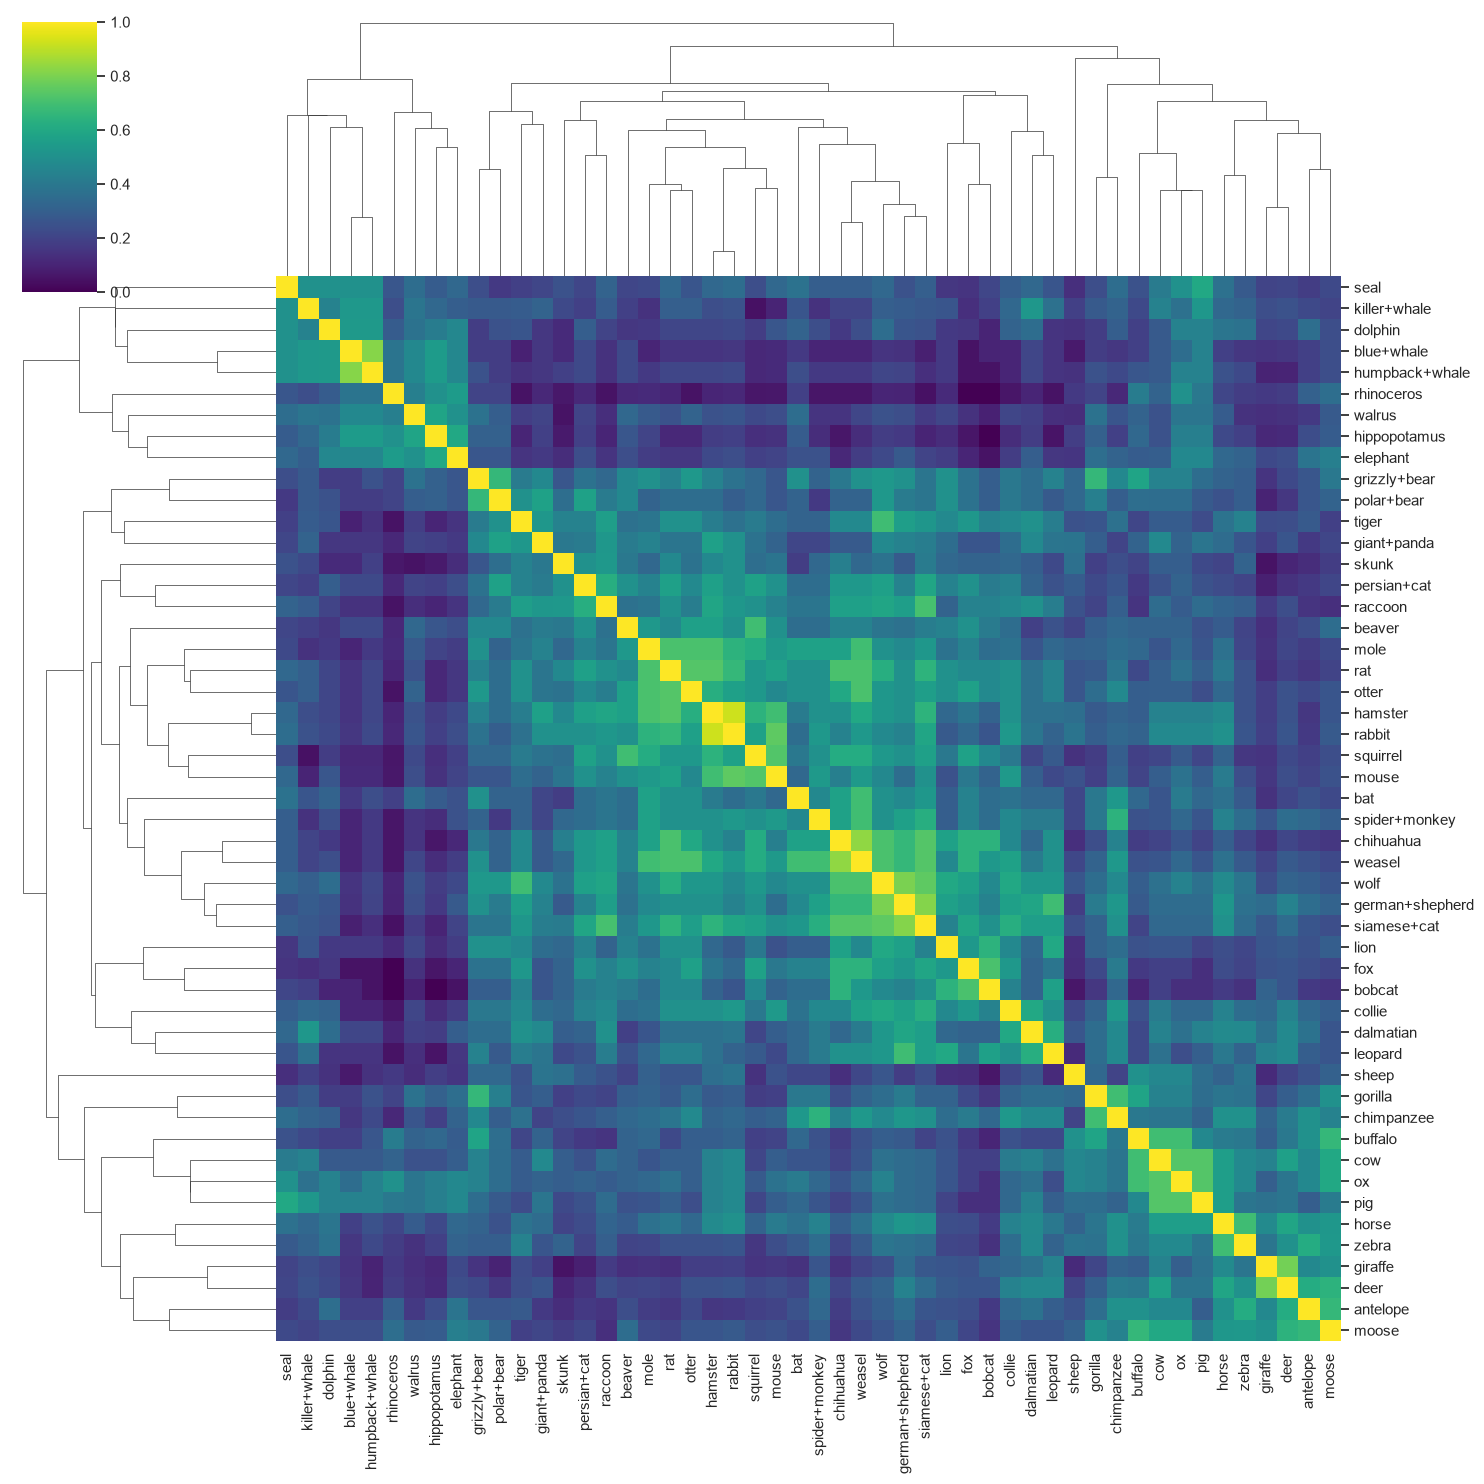

In [38]:
distance_matrix = 1 - similarity_matrix

linkage_matrix = linkage(
    squareform(distance_matrix.to_numpy(), checks=False),
    method="average"
)

sns.clustermap(
    similarity_matrix,
    row_linkage=linkage_matrix,
    col_linkage=linkage_matrix,
    cmap="viridis",
    vmin=0,
    vmax=1,
    figsize=(15, 15)
)

plt.show()

## 4. CLIP Predictions and Confusion Rates

In [47]:
predictions = pd.read_csv(OUT_DIR / "clip_predictions.csv")

print("Number of images:", len(predictions))
print("Number of classes:", predictions["true_label"].nunique())
print("Classification errors:",
      (predictions["true_label"] != predictions["predicted_label"]).sum())

display(predictions.head())

Number of images: 5000
Number of classes: 50
Classification errors: 396


,image_path,true_label,predicted_label
0,antelope/antelope_10014.jpg,antelope,antelope
1,antelope/antelope_10024.jpg,antelope,antelope
2,antelope/antelope_10052.jpg,antelope,antelope
3,antelope/antelope_10055.jpg,antelope,antelope
4,antelope/antelope_10062.jpg,antelope,antelope


## Class-Normalized Confusion Matrix

In [48]:
animals = similarity_matrix.index.tolist()

confusion_counts = pd.crosstab(
    predictions["true_label"],
    predictions["predicted_label"]
).reindex(index=animals, columns=animals, fill_value=0)

confusion_rates = confusion_counts.div(
    confusion_counts.sum(axis=1),
    axis=0
)

print("Confusion matrix shape:", confusion_rates.shape)
display(confusion_rates.iloc[:5, :5])

Confusion matrix shape: (50, 50)


predicted_label,antelope,grizzly+bear,killer+whale,beaver,dalmatian
true_label,,,,,
antelope,0.97,0.00,0.00,0.00,0.00
grizzly+bear,0.00,0.99,0.00,0.00,0.00
killer+whale,0.00,0.00,0.94,0.00,0.00
beaver,0.00,0.00,0.00,0.87,0.00
dalmatian,0.00,0.00,0.00,0.00,0.98


## Pairwise Confusion Rates

In [49]:
pairs_df["confusion_ab"] = [
    confusion_rates.loc[a, b]
    for a, b in zip(pairs_df["animal_1"], pairs_df["animal_2"])
]

pairs_df["confusion_ba"] = [
    confusion_rates.loc[b, a]
    for a, b in zip(pairs_df["animal_1"], pairs_df["animal_2"])
]

pairs_df["mutual_confusion"] = (
    pairs_df["confusion_ab"] + pairs_df["confusion_ba"]
) / 2

display(
    pairs_df.sort_values(
        "mutual_confusion",
        ascending=False
    ).head(15)
)

,animal_1,animal_2,similarity,confusion_ab,confusion_ba,mutual_confusion
372,blue+whale,humpback+whale,0.818182,0.67,0.05,0.360
817,ox,cow,0.733333,0.24,0.10,0.170
805,ox,buffalo,0.692308,0.26,0.00,0.130
1098,rat,mouse,0.571429,0.15,0.05,0.100
175,beaver,otter,0.562500,0.08,0.10,0.090
671,spider+monkey,chimpanzee,0.642857,0.08,0.08,0.080
942,hamster,mouse,0.692308,0.08,0.05,0.065
896,seal,walrus,0.352941,0.06,0.05,0.055
764,gorilla,chimpanzee,0.692308,0.07,0.03,0.050
111,killer+whale,humpback+whale,0.533333,0.05,0.03,0.040


## 5. Similarity vs. Confusion

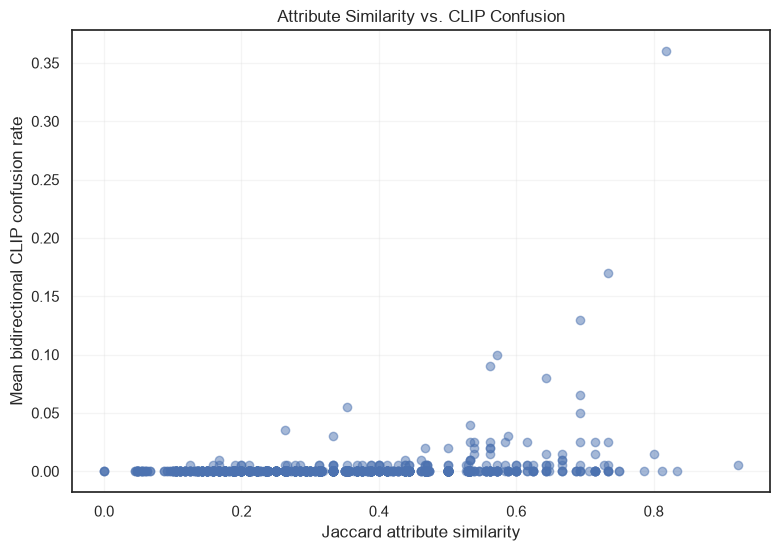

In [50]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pairs_df["similarity"],
    pairs_df["mutual_confusion"],
    alpha=0.5
)

plt.xlabel("Jaccard attribute similarity")
plt.ylabel("Mean bidirectional CLIP confusion rate")
plt.title("Attribute Similarity vs. CLIP Confusion")
plt.grid(alpha=0.2)

plt.show()

## Spearman Correlation

In [59]:
rho, p_value = spearmanr(
    pairs_df["similarity"],
    pairs_df["mutual_confusion"]
)

print(f"Spearman correlation: {rho:.4f}")
print(f"Naive p-value: {p_value:.4e}")

Spearman correlation: 0.2645
Naive p-value: 4.7119e-21


## 6. Permutation Test

In [54]:
animals = similarity_matrix.index.tolist()

S = similarity_matrix.loc[animals, animals].to_numpy()
C = confusion_rates.loc[animals, animals].to_numpy()
C = (C + C.T) / 2

upper = np.triu_indices(len(animals), k=1)

observed_rho = spearmanr(S[upper], C[upper]).statistic

rng = np.random.default_rng(42)
n_permutations = 5000

null_correlations = np.empty(n_permutations)

for i in range(n_permutations):
    perm = rng.permutation(len(animals))
    S_permuted = S[np.ix_(perm, perm)]

    null_correlations[i] = spearmanr(
        S_permuted[upper],
        C[upper]
    ).statistic

p_perm = (
    np.sum(null_correlations >= observed_rho) + 1
) / (n_permutations + 1)

print(f"Observed Spearman rho: {observed_rho:.4f}")
print(f"Permutation p-value: {p_perm:.4f}")

Observed Spearman rho: 0.2645
Permutation p-value: 0.0002


## Permutation Distribution

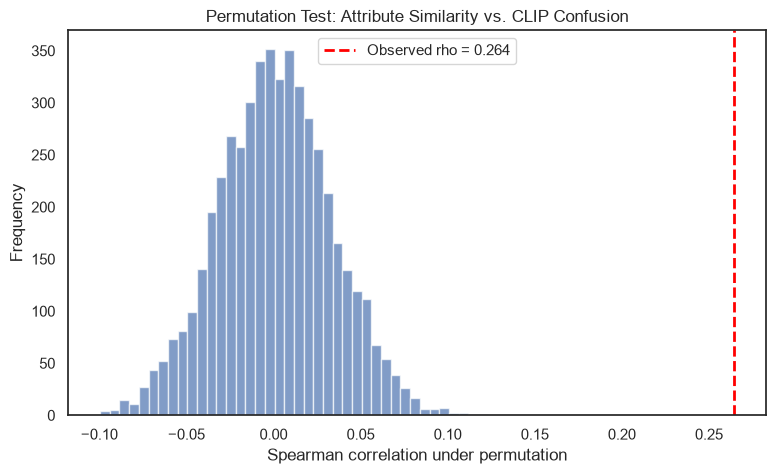

In [52]:
plt.figure(figsize=(9, 5))

plt.hist(
    null_correlations,
    bins=40,
    alpha=0.7
)

plt.axvline(
    observed_rho,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Observed rho = {observed_rho:.3f}"
)

plt.xlabel("Spearman correlation under permutation")
plt.ylabel("Frequency")
plt.title("Permutation Test: Attribute Similarity vs. CLIP Confusion")
plt.legend()
plt.show()

We found a weak positive association between Jaccard attribute similarity and CLIP confusion (Spearman's ρ = 0.2645, class-label permutation p = 0.0002). Many animal pairs with high attribute similarity showed little or no confusion so shared attributes alone dont explain classification behavior.

## 7.  CLIP Misclassifications

Each image is displayed with its ground-truth label, predicted label, and the total number of misclassifications for that pair. 


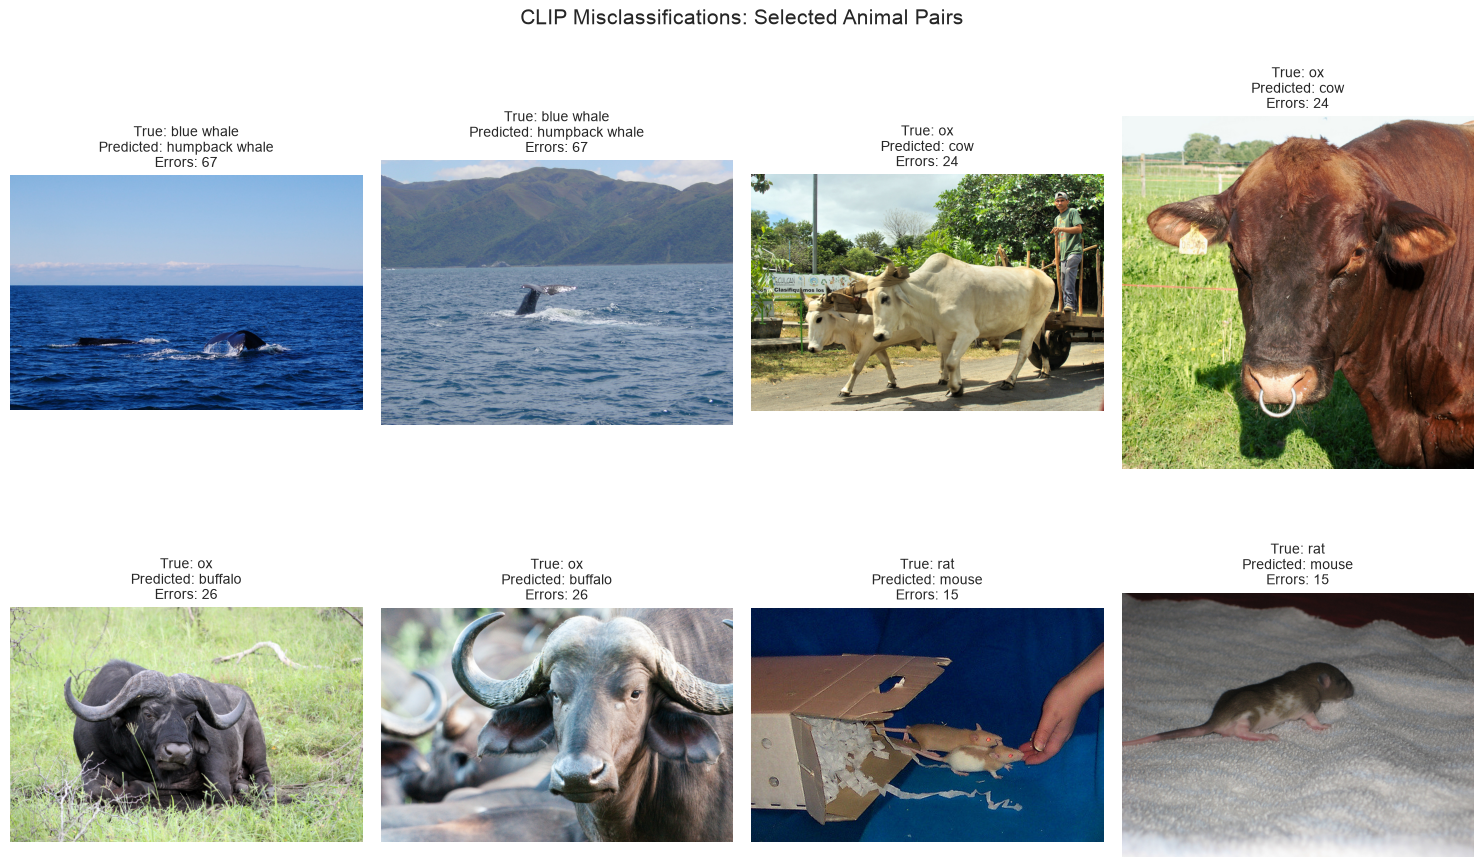

In [64]:
print("Each image is displayed with its ground-truth label, predicted label, and the total number of misclassifications for that pair. ")

image_dir = Path("Animals_with_Attributes2 2/JPEGImages")
# Animal pairs selected from the confusion analysis
selected_pairs = [
    ("blue+whale", "humpback+whale"),
    ("ox", "cow"),
    ("ox", "buffalo"),
    ("rat", "mouse")
]

errors = predictions[
    predictions["true_label"] != predictions["predicted_label"]
]

error_counts = errors.groupby(
    ["true_label", "predicted_label"]
).size()

selected = []

for true_label, predicted_label in selected_pairs:
    examples = errors[
        (errors["true_label"] == true_label) &
        (errors["predicted_label"] == predicted_label)
    ]

    selected.append(examples.head(2))

gallery_df = pd.concat(selected, ignore_index=True).head(9)

fig, axes = plt.subplots(2, 4, figsize=(15, 10))

for ax, (_, row) in zip(axes.flat, gallery_df.iterrows()):
    image_path = image_dir / row["image_path"]

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    true_name = row["true_label"]
    predicted_name = row["predicted_label"]

    count = error_counts.loc[(true_name, predicted_name)]

    ax.set_title(
        f"True: {true_name.replace('+', ' ')}\n"
        f"Predicted: {predicted_name.replace('+', ' ')}\n"
        f"Errors: {count}",
        fontsize=10
    )
    ax.axis("off")

for ax in axes.flat[len(gallery_df):]:
    ax.axis("off")

plt.suptitle("CLIP Misclassifications: Selected Animal Pairs", fontsize=15)
plt.tight_layout()
plt.show()